In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xgcm

In [ ]:
face1 = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320').isel(face=1)
face4 = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320').isel(face=4)
face6 = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320').isel(face=6)
face11 = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320').isel(face=11)

/tmp/ipykernel_3089014/1721293093.py:1: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  face1 = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320').isel(face=1)
/tmp/ipykernel_3089014/1721293093.py:2: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting c

In [ ]:
rows = [
    ('U', face1.U.isel(k=0, time=0), face4.U.isel(k=0, time=0), 'seismic', False),
    ('SN',    face1.SN,                      face4.SN,                      'RdBu_r',  True),
    ('CS',    face1.CS,                      face4.CS,                      'RdBu_r',  True),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 15), layout='constrained')

for i, (name, a, b, cmap, symmetric) in enumerate(rows):
    da = np.squeeze(np.asarray(a.values))
    db = np.squeeze(np.asarray(b.values))

    # One shared color scale per row
    lo = np.nanmin([np.nanmin(da), np.nanmin(db)])
    hi = np.nanmax([np.nanmax(da), np.nanmax(db)])
    if symmetric:
        m = max(abs(lo), abs(hi))
        lo, hi = -m, m
    norm = mcolors.Normalize(vmin=lo, vmax=hi)

    for j, (data, face) in enumerate([(da, 'face1'), (db, 'face4')]):
        ax = axes[i, j]
        pc = ax.pcolormesh(data, cmap=cmap, norm=norm)
        ax.set_title(f'{face}: {name}', fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect('equal')

    # One colorbar per row, spanning both panels in that row
    fig.colorbar(pc, ax=list(axes[i]), label=name, shrink=0.9)

fig.suptitle('face1 vs face4', fontsize=15, fontweight='bold')
plt.show()

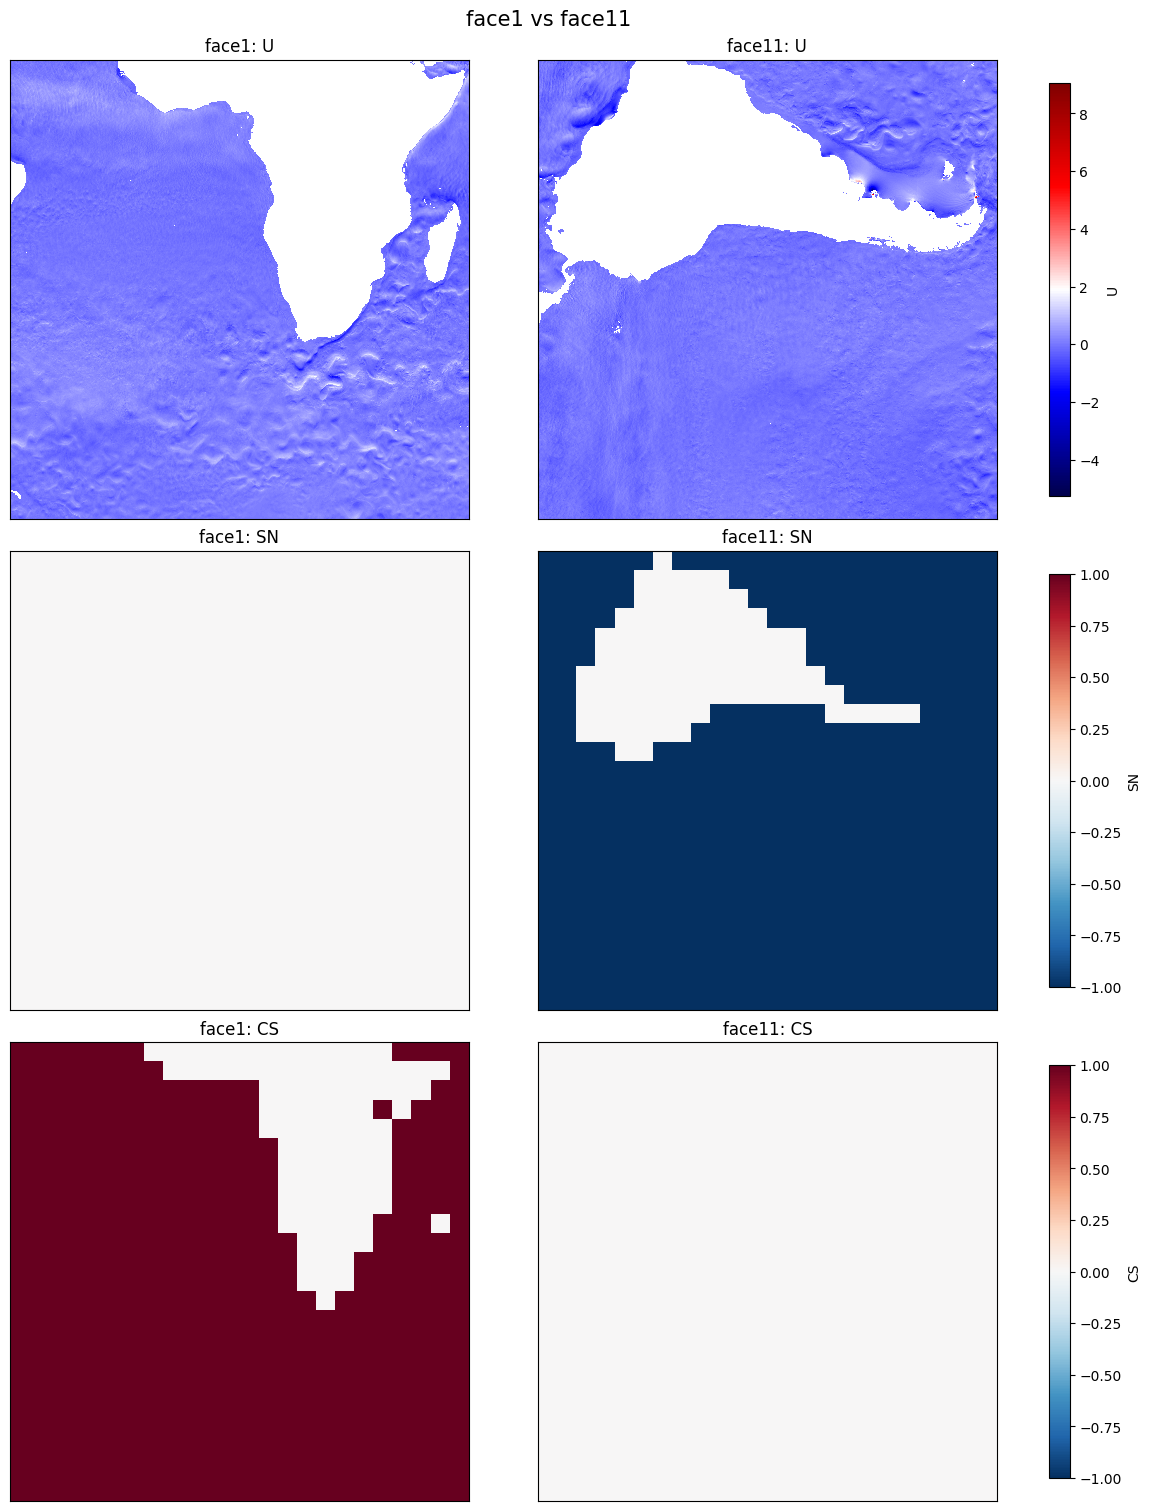

In [7]:
rows = [
    ('U', face1.U.isel(k=0, time=0), face11.U.isel(k=0, time=0), 'seismic', False),
    ('SN',    face1.SN,                      face11.SN,                      'RdBu_r',  True),
    ('CS',    face1.CS,                      face11.CS,                      'RdBu_r',  True),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 15), layout='constrained')

for i, (name, a, b, cmap, symmetric) in enumerate(rows):
    da = np.squeeze(np.asarray(a.values))
    db = np.squeeze(np.asarray(b.values))

    # One shared color scale per row
    lo = np.nanmin([np.nanmin(da), np.nanmin(db)])
    hi = np.nanmax([np.nanmax(da), np.nanmax(db)])
    if symmetric:
        m = max(abs(lo), abs(hi))
        lo, hi = -m, m
    norm = mcolors.Normalize(vmin=lo, vmax=hi)

    for j, (data, face) in enumerate([(da, 'face1'), (db, 'face11')]):
        ax = axes[i, j]
        pc = ax.pcolormesh(data, cmap=cmap, norm=norm)
        ax.set_title(f'{face}: {name}', fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect('equal')

    # One colorbar per row, spanning both panels in that row
    fig.colorbar(pc, ax=list(axes[i]), label=name, shrink=0.9)

fig.suptitle('face1 vs face11', fontsize=15, fontweight='bold')
plt.show()

In [38]:
# overwrite U and V with SN and CS rotations (so all U is zonal and all V is meridional across all faces)
# formula is: u_px * CS_px - v_px * SN_px and v (meridional) = u_px * SN_px + v_px * CS_px, where _px is the value at a given pixel

In [6]:
def interp_to_center(ds, u="U", v="V"):
    """Interpolate a staggered (u on i_g, v on j_g) vector pair onto cell centers (j, i).
    Works on any face/slice/time/depth selection, and on any C-grid pair (U/V, oceTAUX/oceTAUY, ...)."""
    coords = {"X": {"center": "i", "left": "i_g"}, "Y": {"center": "j", "left": "j_g"}}  # i_g/j_g are left edges, same length as i/j
    if "k" in ds.dims and "k_p1" in ds.dims:
        coords["Z"] = {"center": "k", "outer": "k_p1"}
    grid = xgcm.Grid(ds, coords=coords, periodic=False, autoparse_metadata=False)
    u_c = grid.interp(ds[u], axis="X", boundary="extend").drop_vars("i_g", errors="ignore").reset_coords(drop=True)
    v_c = grid.interp(ds[v], axis="Y", boundary="extend").drop_vars("j_g", errors="ignore").reset_coords(drop=True)
    return u_c, v_c

def rotate_to_geo(ds, u="U", v="V", suffix=("_zonal", "_meridional")):
    """Add eastward/northward components (e.g. U_zonal, V_meridional) at cell centers."""
    u_c, v_c = interp_to_center(ds, u, v)
    ds[u + suffix[0]] = u_c * ds.CS - v_c * ds.SN
    ds[v + suffix[1]] = u_c * ds.SN + v_c * ds.CS
    return ds

In [7]:
face6_rot = rotate_to_geo(face6.isel(time=0, k=0))

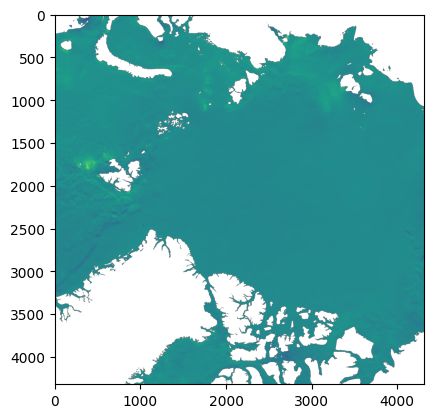

In [8]:
plt.imshow(face6.isel(time=0, k=0).U)

In [ ]:
plt.imshow(face6_rot.U_zonal - face6.isel(time=0, k=0).U)

A west edge : [-0.06673335 -0.06526721 -0.06660707 -0.07075557 -0.07583647]
B east edge : [-0.06207098 -0.05205715 -0.0544845  -0.05956951 -0.0625807 ]


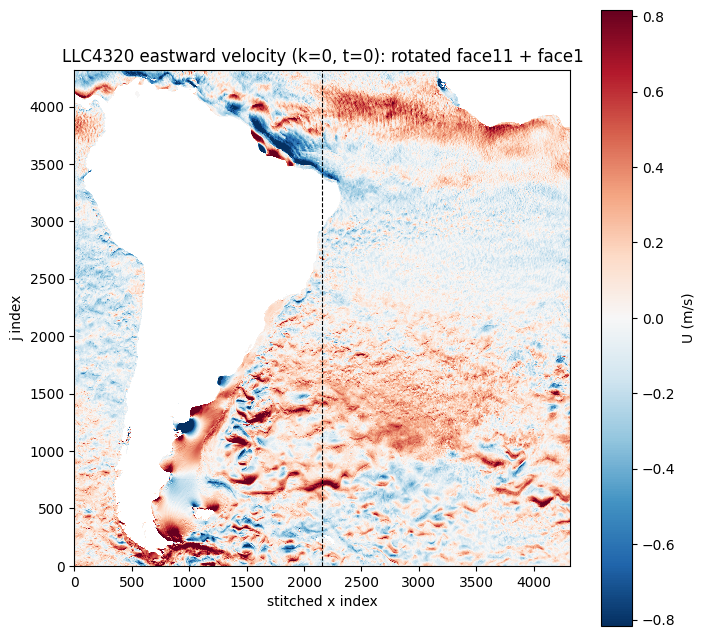

In [40]:
t, k = 0, 0
face1_sel = rotate_to_geo(face1.isel(time=t, k=k, i=slice(0, 4320//2), i_g=slice(0, 4320//2)))
face11_sel = rotate_to_geo(face11.isel(time=t, k=k, j=slice(4320//2, 4320), j_g=slice(4320//2, 4320)))

# face1 west half; its west edge (i_g=0) borders face11's north edge (j=max)
A = face1_sel.U_zonal.values         # (4320, 2160)
B = face11_sel.U_zonal.values

# Rotate 90° CCW so face11's north edge becomes the east column, then put it west of A
B_rot = np.rot90(B, k=1)                                              # (4320, 2160)

# Seam check: these should match closely (corr ~0.99)
print("A west edge :", A[2000:2005, 0])
print("B east edge :", B_rot[2000:2005, -1])

stitched = np.hstack([B_rot, A])                                      # (4320, 4320)

fig, ax = plt.subplots(figsize=(8, 8))
vmax = np.nanpercentile(np.abs(stitched), 99)
pc = ax.pcolormesh(stitched, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto", rasterized=True)
ax.axvline(B_rot.shape[1] - 0.5, color="k", ls="--", lw=0.8)   # face seam
ax.set_aspect("equal")
ax.set_title("LLC4320 eastward velocity (k=0, t=0): rotated face11 + face1")
ax.set_xlabel("stitched x index")
ax.set_ylabel("j index")
plt.colorbar(pc, ax=ax, label="U (m/s)")
plt.show()

In [41]:
llc = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320')

/tmp/ipykernel_379931/3049893463.py:1: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  llc = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320')


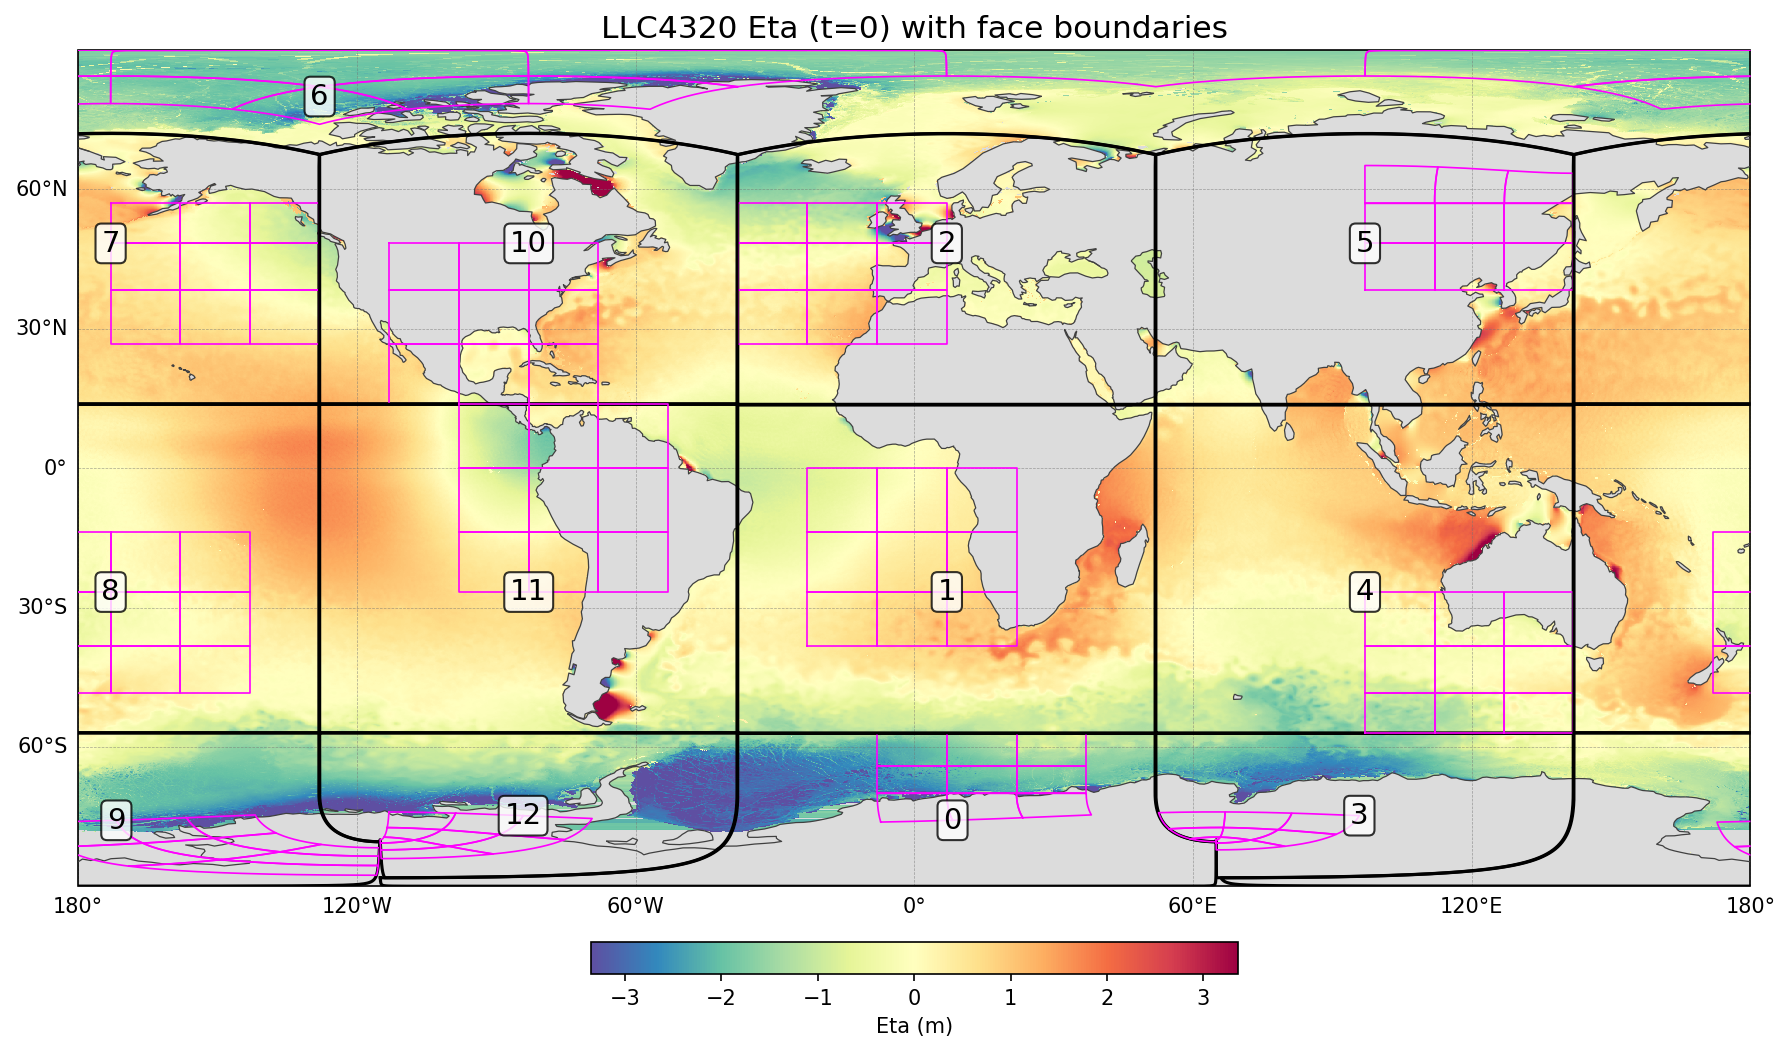

In [50]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker

stride = 8  # subsample for plotting
eta = llc.Eta.isel(time=0, i=slice(None, None, stride), j=slice(None, None, stride)).compute()
xc = llc.XC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()
yc = llc.YC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()

eta = eta.where(eta != 0.0)
vlim = float(np.nanpercentile(np.abs(eta.values), 98))
norm = mcolors.TwoSlopeNorm(vmin=-vlim, vcenter=0.0, vmax=vlim)

data_crs = ccrs.PlateCarree()
fig = plt.figure(figsize=(15, 8), dpi=150)
ax = plt.axes(projection=data_crs)
ax.set_global()
ax.set_facecolor("gainsboro")
ax.add_feature(cfeature.LAND, facecolor="gainsboro", edgecolor="none", zorder=2)
ax.coastlines(linewidth=0.6, color="0.25", zorder=3)

def face_perimeter(a):
    """Values along a face's edge, walked counterclockwise in (j, i)."""
    return np.concatenate([a[0, :], a[1:, -1], a[-1, -2::-1], a[-2::-1, 0]])

tile, ntile = 720 // stride, 3      # 720px tiles in subsampled index units, 3x3 block
rng = np.random.default_rng(0)

for face in llc.face.values:
    lon, lat = xc.sel(face=face).values, yc.sel(face=face).values
    n_slots = lon.shape[0] // tile - ntile + 1   # tile-aligned starts per axis: 4
    # Split face at the dateline so pcolormesh doesn't smear cells across the map
    for wrap in (lon, np.where(lon < 0, lon + 360, lon)):
        pcm = ax.pcolormesh(wrap, lat, eta.sel(face=face).values, transform=data_crs,
                            cmap="Spectral_r", norm=norm, shading="auto", rasterized=True, zorder=1)

    # Geodetic draws edges as great-circle segments and handles dateline wrapping
    ax.plot(face_perimeter(lon), face_perimeter(lat), transform=ccrs.Geodetic(), color="k", lw=1.5, zorder=5)

    # Random tile-aligned 3x3 block: starts at multiples of 90 (= 720 full-res px)
    j0, i0 = rng.integers(0, n_slots, size=2) * tile
    for a in range(ntile):
        for b in range(ntile):
            js = slice(j0 + a * tile, j0 + (a + 1) * tile + 1)
            is_ = slice(i0 + b * tile, i0 + (b + 1) * tile + 1)
            ax.plot(face_perimeter(lon[js, is_]), face_perimeter(lat[js, is_]),
                    transform=ccrs.Geodetic(), color="magenta", lw=0.8, zorder=5)

    jc, ic = lon.shape[0] // 2, lon.shape[1] // 2
    ax.text(lon[jc, ic], min(lat[jc, ic], 80),  # keep Arctic face label on-map
            str(face), transform=data_crs, fontsize=14, fontweight="bold",
            ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="k", alpha=0.8))

gl = ax.gridlines(crs=data_crs, draw_labels=True, linewidth=0.35, color="0.45", alpha=0.6, linestyle="--")
gl.top_labels = gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

cbar = fig.colorbar(pcm, ax=ax, orientation="horizontal", pad=0.06, shrink=0.55, fraction=0.035)
cbar.set_label("Eta (m)")
ax.set_title("LLC4320 Eta (t=0) with face boundaries", fontsize=15)
plt.show()

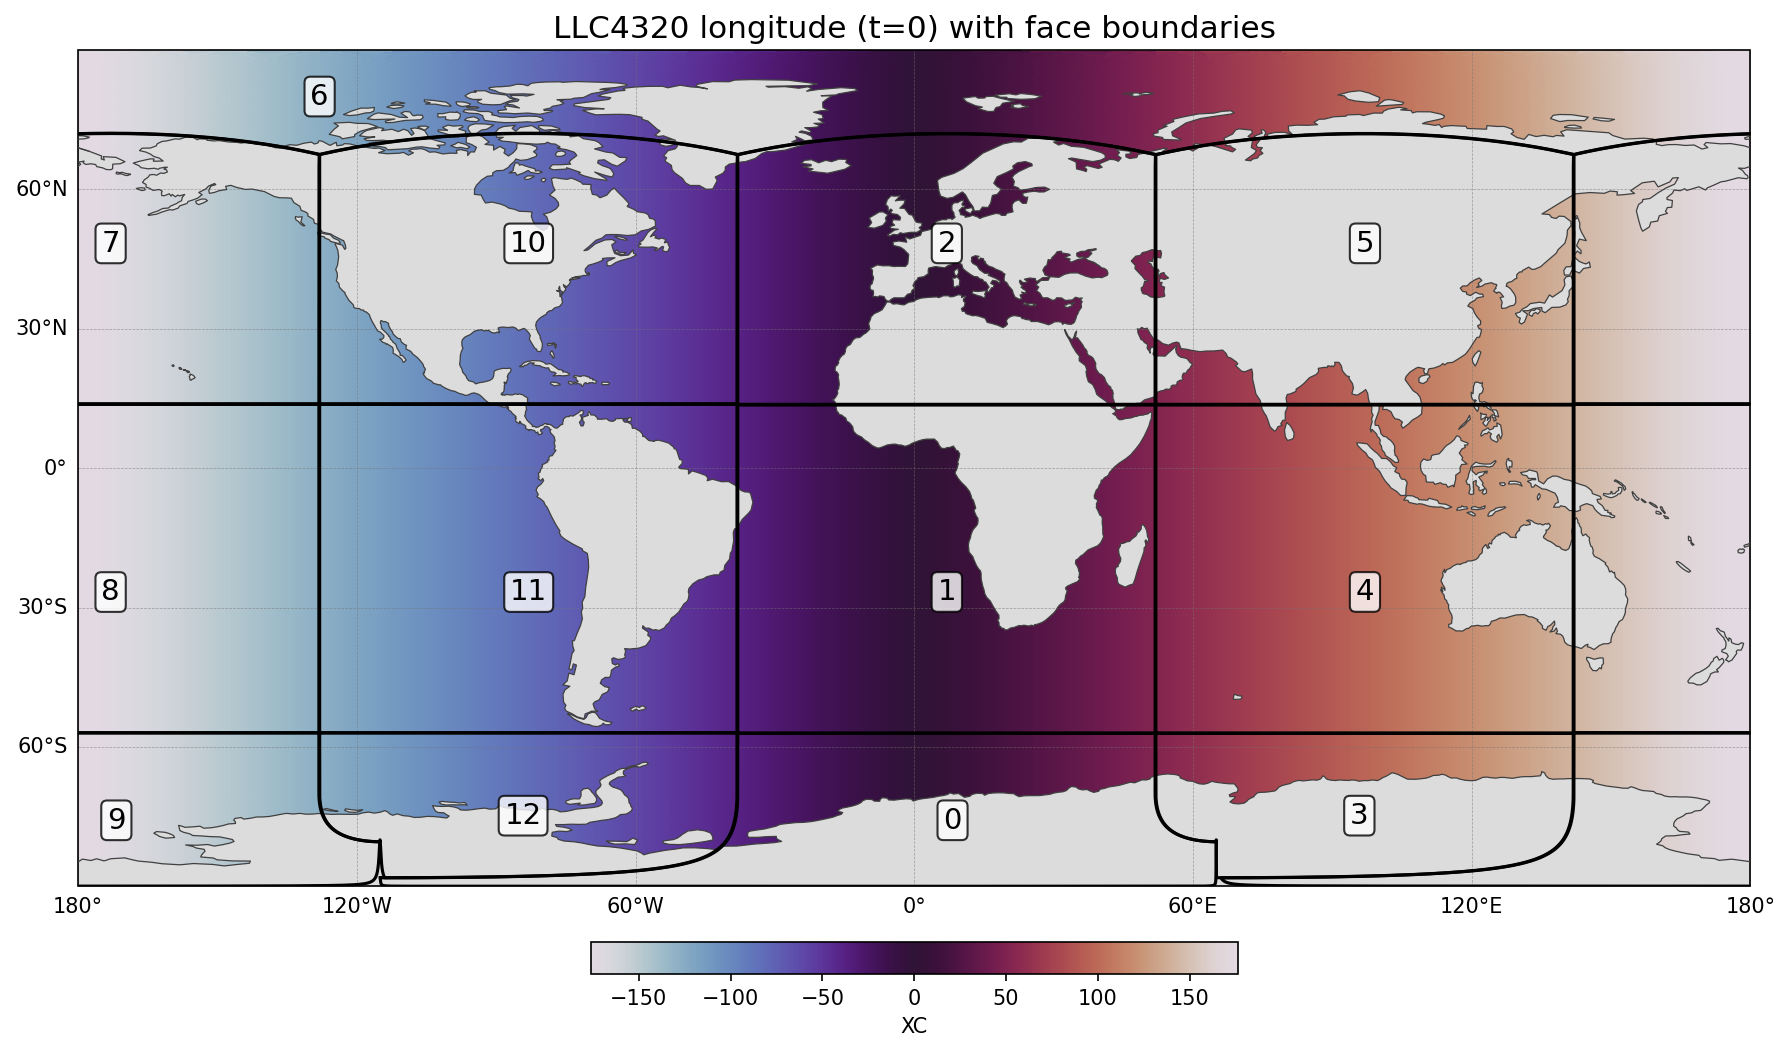

In [45]:

stride = 8  # subsample for plotting
eta = llc.XC.isel( i=slice(None, None, stride), j=slice(None, None, stride)).compute()
xc = llc.XC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()
yc = llc.YC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()

eta = eta.where(eta != 0.0)
vlim = float(np.nanpercentile(np.abs(eta.values), 98))
norm = mcolors.TwoSlopeNorm(vmin=-vlim, vcenter=0.0, vmax=vlim)

data_crs = ccrs.PlateCarree()
fig = plt.figure(figsize=(15, 8), dpi=150)
ax = plt.axes(projection=data_crs)
ax.set_global()
ax.set_facecolor("gainsboro")
ax.add_feature(cfeature.LAND, facecolor="gainsboro", edgecolor="none", zorder=2)
ax.coastlines(linewidth=0.6, color="0.25", zorder=3)

def face_perimeter(a):
    """Values along a face's edge, walked counterclockwise in (j, i)."""
    return np.concatenate([a[0, :], a[1:, -1], a[-1, -2::-1], a[-2::-1, 0]])

for face in llc.face.values:
    lon, lat = xc.sel(face=face).values, yc.sel(face=face).values
    # Split face at the dateline so pcolormesh doesn't smear cells across the map
    for wrap in (lon, np.where(lon < 0, lon + 360, lon)):
        pcm = ax.pcolormesh(wrap, lat, eta.sel(face=face).values, transform=data_crs,
                            cmap="twilight", norm=norm, shading="auto", rasterized=True, zorder=1)

    # Geodetic draws edges as great-circle segments and handles dateline wrapping
    ax.plot(face_perimeter(lon), face_perimeter(lat), transform=ccrs.Geodetic(), color="k", lw=1.5, zorder=5)
    jc, ic = lon.shape[0] // 2, lon.shape[1] // 2
    ax.text(lon[jc, ic], min(lat[jc, ic], 80),  # keep Arctic face label on-map
            str(face), transform=data_crs, fontsize=14, fontweight="bold",
            ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="k", alpha=0.8))

gl = ax.gridlines(crs=data_crs, draw_labels=True, linewidth=0.35, color="0.45", alpha=0.6, linestyle="--")
gl.top_labels = gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

cbar = fig.colorbar(pcm, ax=ax, orientation="horizontal", pad=0.06, shrink=0.55, fraction=0.035)
cbar.set_label("XC")
ax.set_title("LLC4320 longitude (t=0) with face boundaries", fontsize=15)
plt.show()

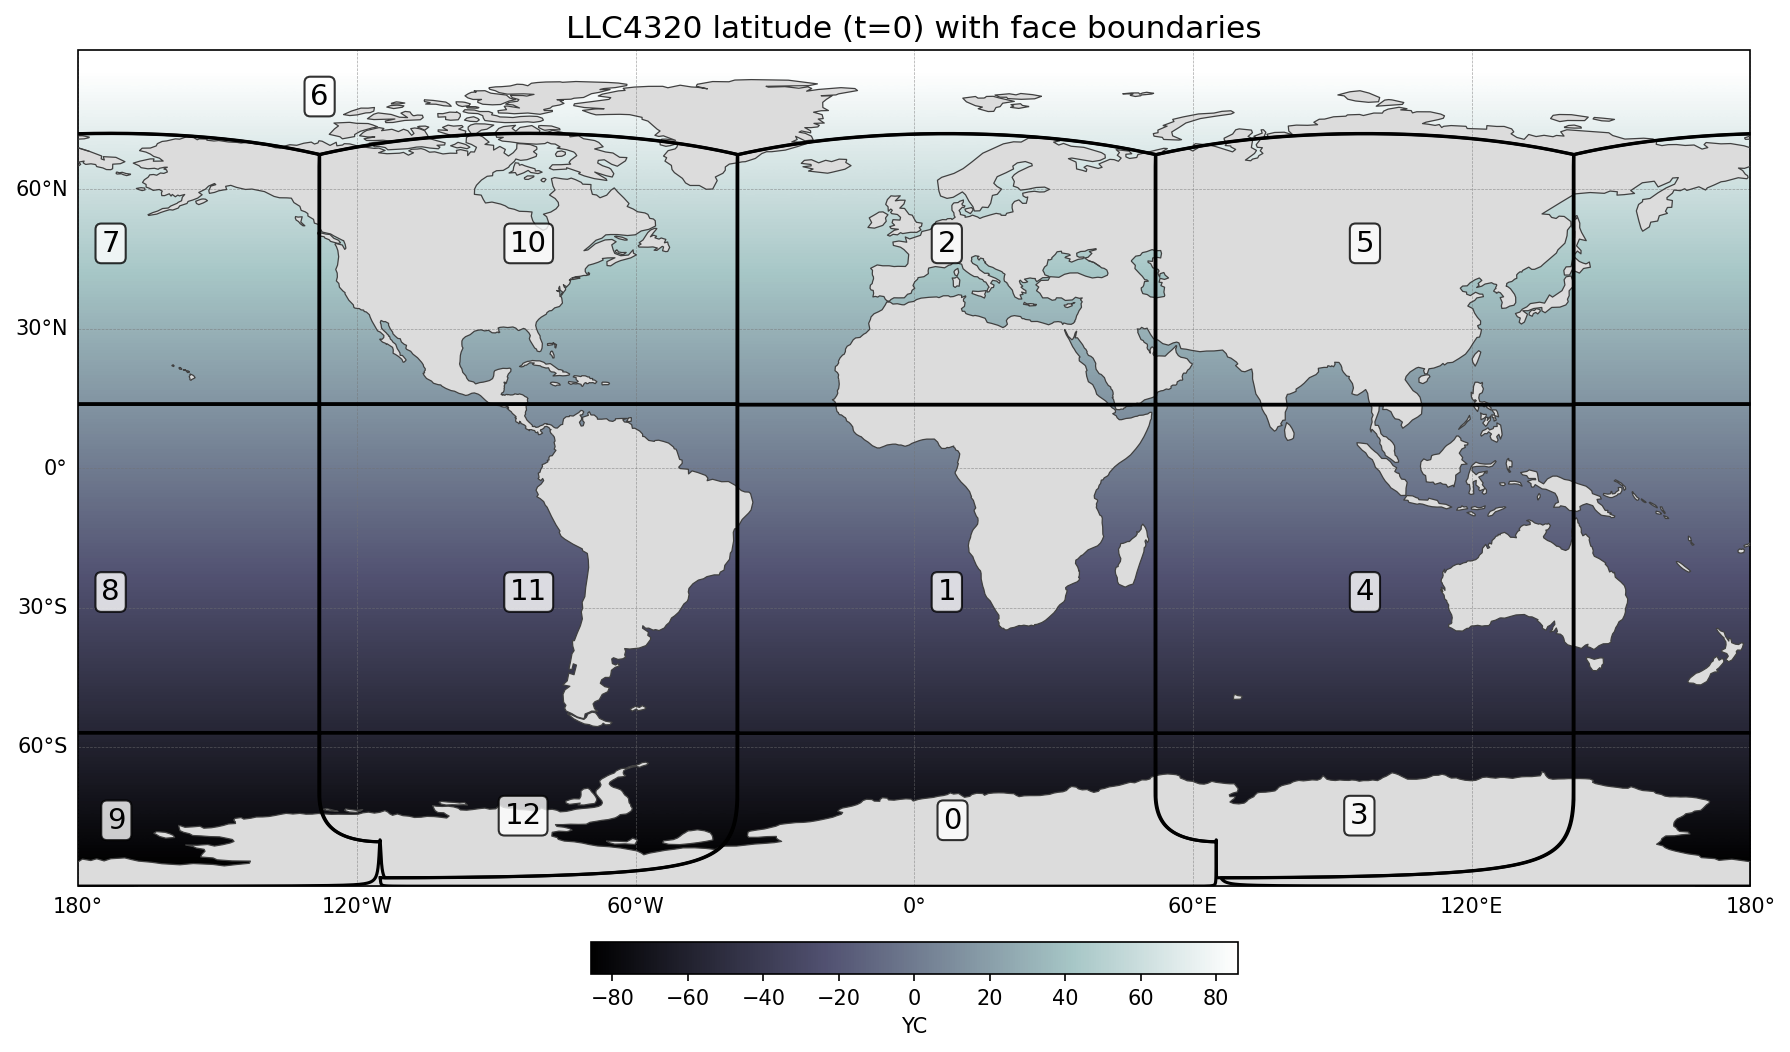

In [47]:

stride = 8  # subsample for plotting
eta = llc.YC.isel( i=slice(None, None, stride), j=slice(None, None, stride)).compute()
xc = llc.XC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()
yc = llc.YC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()

eta = eta.where(eta != 0.0)
vlim = float(np.nanpercentile(np.abs(eta.values), 98))
norm = mcolors.TwoSlopeNorm(vmin=-vlim, vcenter=0.0, vmax=vlim)

data_crs = ccrs.PlateCarree()
fig = plt.figure(figsize=(15, 8), dpi=150)
ax = plt.axes(projection=data_crs)
ax.set_global()
ax.set_facecolor("gainsboro")
ax.add_feature(cfeature.LAND, facecolor="gainsboro", edgecolor="none", zorder=2)
ax.coastlines(linewidth=0.6, color="0.25", zorder=3)

def face_perimeter(a):
    """Values along a face's edge, walked counterclockwise in (j, i)."""
    return np.concatenate([a[0, :], a[1:, -1], a[-1, -2::-1], a[-2::-1, 0]])

for face in llc.face.values:
    lon, lat = xc.sel(face=face).values, yc.sel(face=face).values
    # Split face at the dateline so pcolormesh doesn't smear cells across the map
    for wrap in (lon, np.where(lon < 0, lon + 360, lon)):
        pcm = ax.pcolormesh(wrap, lat, eta.sel(face=face).values, transform=data_crs,
                            cmap="bone", norm=norm, shading="auto", rasterized=True, zorder=1)

    # Geodetic draws edges as great-circle segments and handles dateline wrapping
    ax.plot(face_perimeter(lon), face_perimeter(lat), transform=ccrs.Geodetic(), color="k", lw=1.5, zorder=5)
    jc, ic = lon.shape[0] // 2, lon.shape[1] // 2
    ax.text(lon[jc, ic], min(lat[jc, ic], 80),  # keep Arctic face label on-map
            str(face), transform=data_crs, fontsize=14, fontweight="bold",
            ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="k", alpha=0.8))

gl = ax.gridlines(crs=data_crs, draw_labels=True, linewidth=0.35, color="0.45", alpha=0.6, linestyle="--")
gl.top_labels = gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

cbar = fig.colorbar(pcm, ax=ax, orientation="horizontal", pad=0.06, shrink=0.55, fraction=0.035)
cbar.set_label("YC")
ax.set_title("LLC4320 latitude (t=0) with face boundaries", fontsize=15)
plt.show()

In [54]:
llc

<xarray.Dataset> Size: 3PB
Dimensions:      (face: 13, j: 4320, i: 4320, time: 10311, k: 51, k_p1: 52,
                  i_g: 4320, j_g: 4320, k_l: 51, k_u: 51)
Coordinates:
  * face         (face) int16 26B 0 1 2 3 4 5 6 7 8 9 10 11 12
  * j            (j) int16 9kB 0 1 2 3 4 5 6 ... 4314 4315 4316 4317 4318 4319
  * i            (i) int16 9kB 0 1 2 3 4 5 6 ... 4314 4315 4316 4317 4318 4319
  * time         (time) datetime64[ns] 82kB 2011-09-13 ... 2012-11-15T14:00:00
  * k            (k) int16 102B 0 1 2 3 4 5 6 7 8 ... 42 43 44 45 46 47 48 49 50
  * k_p1         (k_p1) int64 416B 0 1 2 3 4 5 6 7 8 ... 44 45 46 47 48 49 50 51
  * i_g          (i_g) int16 9kB 0 1 2 3 4 5 6 ... 4314 4315 4316 4317 4318 4319
  * j_g          (j_g) int16 9kB 0 1 2 3 4 5 6 ... 4314 4315 4316 4317 4318 4319
  * k_l          (k_l) int64 408B 0 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * k_u          (k_u) int64 408B 0 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
Data variables: (12/57)
    CS           (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    Depth        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    Eta          (time, face, j, i) float32 10TB dask.array<chunksize=(1, 13, 4320, 4320), meta=np.ndarray>
    KPPhbl       (time, face, j, i) float32 10TB dask.array<chunksize=(1, 13, 4320, 4320), meta=np.ndarray>
    PHrefC       (k) float32 204B dask.array<chunksize=(51,), meta=np.ndarray>
    PHrefF       (k_p1) float32 208B dask.array<chunksize=(52,), meta=np.ndarray>
    ...           ...
    oceTAUY      (time, face, j_g, i) float32 10TB dask.array<chunksize=(1, 13, 4320, 4320), meta=np.ndarray>
    rA           (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    rAs          (face, j_g, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    rAw          (face, j, i_g) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    rAz          (face, j_g, i_g) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    rhoRef       (k) float32 204B dask.array<chunksize=(51,), meta=np.ndarray>

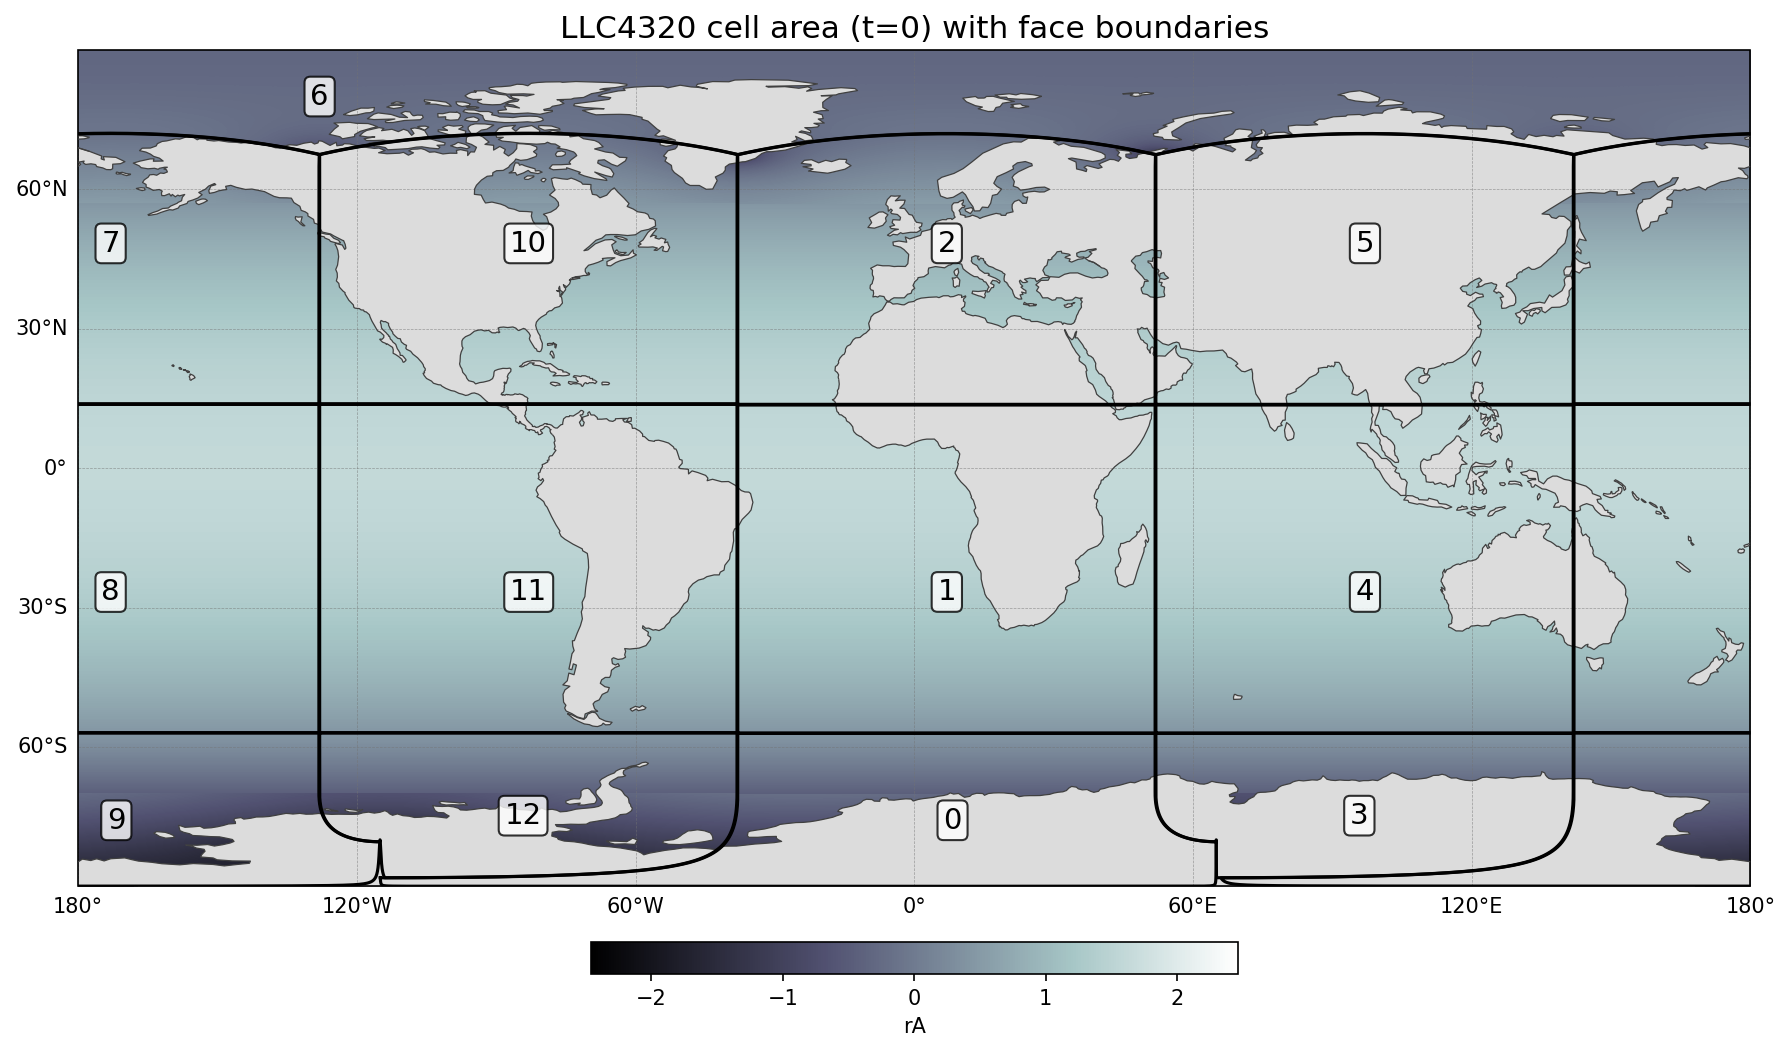

In [53]:

stride = 8  # subsample for plotting
eta = np.log(llc.rA.isel( i=slice(None, None, stride), j=slice(None, None, stride)).compute() / 1000000)
xc = llc.XC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()
yc = llc.YC.isel(i=slice(None, None, stride), j=slice(None, None, stride)).compute()

eta = eta.where(eta != 0.0)
vlim = float(np.nanpercentile(np.abs(eta.values), 98))
norm = mcolors.TwoSlopeNorm(vmin=-vlim, vcenter=0.0, vmax=vlim)

data_crs = ccrs.PlateCarree()
fig = plt.figure(figsize=(15, 8), dpi=150)
ax = plt.axes(projection=data_crs)
ax.set_global()
ax.set_facecolor("gainsboro")
ax.add_feature(cfeature.LAND, facecolor="gainsboro", edgecolor="none", zorder=2)
ax.coastlines(linewidth=0.6, color="0.25", zorder=3)

def face_perimeter(a):
    """Values along a face's edge, walked counterclockwise in (j, i)."""
    return np.concatenate([a[0, :], a[1:, -1], a[-1, -2::-1], a[-2::-1, 0]])

for face in llc.face.values:
    lon, lat = xc.sel(face=face).values, yc.sel(face=face).values
    # Split face at the dateline so pcolormesh doesn't smear cells across the map
    for wrap in (lon, np.where(lon < 0, lon + 360, lon)):
        pcm = ax.pcolormesh(wrap, lat, eta.sel(face=face).values, transform=data_crs,
                            cmap="bone", norm=norm, shading="auto", rasterized=True, zorder=1)

    # Geodetic draws edges as great-circle segments and handles dateline wrapping
    ax.plot(face_perimeter(lon), face_perimeter(lat), transform=ccrs.Geodetic(), color="k", lw=1.5, zorder=5)
    jc, ic = lon.shape[0] // 2, lon.shape[1] // 2
    ax.text(lon[jc, ic], min(lat[jc, ic], 80),  # keep Arctic face label on-map
            str(face), transform=data_crs, fontsize=14, fontweight="bold",
            ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="k", alpha=0.8))

gl = ax.gridlines(crs=data_crs, draw_labels=True, linewidth=0.35, color="0.45", alpha=0.6, linestyle="--")
gl.top_labels = gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

cbar = fig.colorbar(pcm, ax=ax, orientation="horizontal", pad=0.06, shrink=0.55, fraction=0.035)
cbar.set_label("rA")
ax.set_title("LLC4320 cell area (t=0) with face boundaries", fontsize=15)
plt.show()